
# FlotIQ | Predicción de precios eléctricos

## 02. Modelos de referencia (Baseline)

**Objetivo:** establecer una referencia de precisión para
predecir el precio mayorista de la electricidad en España.

Antes de entrenar modelos de Machine Learning, evaluaremos
dos estrategias sencillas:

- **Baseline 48 h:** utilizar el precio observado 48 horas antes.
- **Baseline semanal:** utilizar el precio observado 168 horas antes.

### Metodología

Utilizaremos datos históricos de OMIE, unificados a
frecuencia horaria y expresados en €/MWh.

Reservaremos los últimos 90 días como conjunto de prueba.

**Métricas:** MAE y RMSE.

Los modelos posteriores deberán mejorar estos resultados
sin utilizar información futura.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)

pd.set_option("display.max_columns", None)

print("FlotIQ | Bibliotecas cargadas correctamente")


FlotIQ | Bibliotecas cargadas correctamente


In [4]:

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "omie_ml_hourly.parquet"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encuentra el dataset: {DATA_PATH}"
    )

df = pd.read_parquet(DATA_PATH)

df["datetime_utc"] = pd.to_datetime(
    df["datetime_utc"],
    utc=True,
)

df = df.sort_values(
    "datetime_utc"
).reset_index(drop=True)

print("Filas:", len(df))
print("Columnas:", len(df.columns))
print("Primera fecha:", df["datetime_utc"].min())
print("Última fecha:", df["datetime_utc"].max())

display(df.head(2))


Filas: 32640
Columnas: 15
Primera fecha: 2023-01-09 22:00:00+00:00
Última fecha: 2026-09-30 21:00:00+00:00


,datetime_utc,price_eur_mwh,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,month_sin,month_cos,price_lag_48h,price_lag_72h,price_lag_168h,price_rolling_mean_24h,price_rolling_mean_168h
0,2023-01-09 22:00:00+00:00,106.34,23,0,1,0,-0.258819,0.965926,0.5,0.866025,24.61,91.10,124.22,23.773750,87.198512
1,2023-01-09 23:00:00+00:00,105.98,0,1,1,0,0.000000,1.000000,0.5,0.866025,7.00,53.42,130.01,21.839583,87.240179


In [3]:

TEST_DAYS = 90

test_start = (
    df["datetime_utc"].max()
    - pd.Timedelta(days=TEST_DAYS)
    + pd.Timedelta(hours=1)
)

train = df[
    df["datetime_utc"] < test_start
].copy()

test = df[
    df["datetime_utc"] >= test_start
].copy()

print("Entrenamiento:", len(train), "filas")
print("Prueba:", len(test), "filas")
print()
print("Inicio prueba:", test["datetime_utc"].min())
print("Final prueba:", test["datetime_utc"].max())

assert len(test) == 90 * 24, (
    "El conjunto de prueba no contiene 90 días completos."
)

assert train["datetime_utc"].max() < test["datetime_utc"].min()

print("\nDivisión temporal correcta")


Entrenamiento: 30480 filas
Prueba: 2160 filas

Inicio prueba: 2026-07-02 22:00:00+00:00
Final prueba: 2026-09-30 21:00:00+00:00

División temporal correcta


In [5]:

# ============================================
# FLOTIQ | EVALUACIÓN DE BASELINES
# ============================================

# Precio real observado
y_real = test["price_eur_mwh"]

# Predicción basada en precios anteriores
test["pred_48h"] = test["price_lag_48h"]
test["pred_168h"] = test["price_lag_168h"]

resultados = []

for nombre, columna in [
    ("Baseline 48 horas", "pred_48h"),
    ("Baseline semanal", "pred_168h"),
]:
    y_pred = test[columna]

    mae = mean_absolute_error(y_real, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_real, y_pred)
    )

    resultados.append({
        "Modelo": nombre,
        "MAE (€/MWh)": round(mae, 2),
        "RMSE (€/MWh)": round(rmse, 2),
    })

resultados_df = pd.DataFrame(resultados)

display(
    resultados_df.sort_values("MAE (€/MWh)")
)


,Modelo,MAE (€/MWh),RMSE (€/MWh)
1,Baseline semanal,27.66,39.18
0,Baseline 48 horas,30.37,43.29


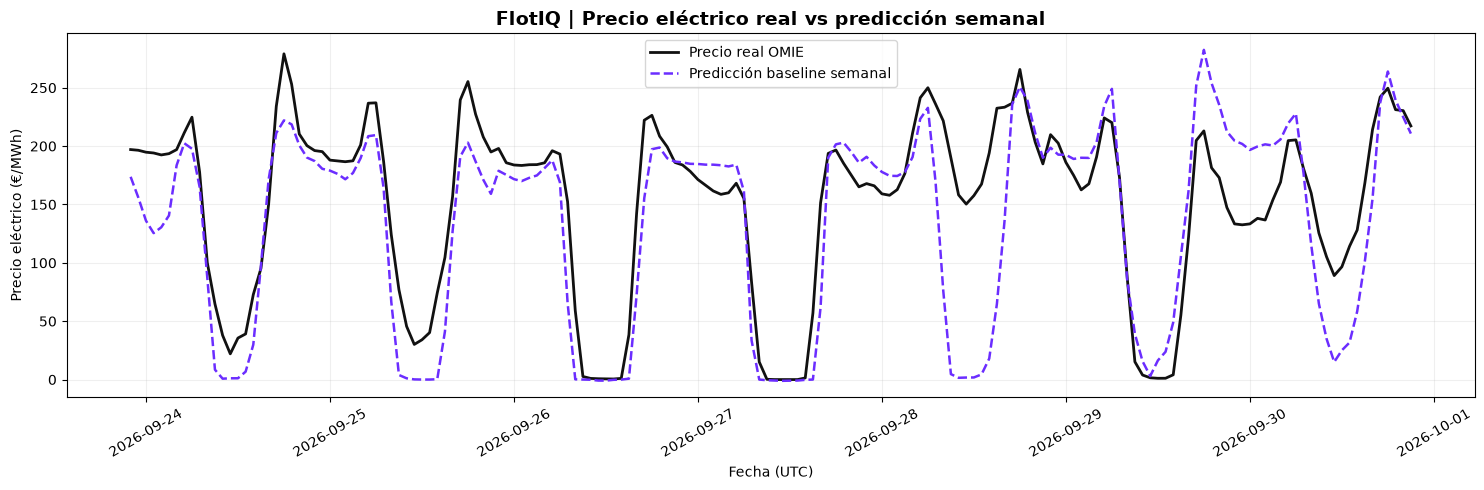

In [ ]:

#PRECIO REAL VS BASELINE SEMANAL
# ============================================

# Visualizar los últimos 7 días del test
semana = test.tail(24 * 7).copy()

plt.figure(figsize=(15, 5))

plt.plot(
    semana["datetime_utc"],
    semana["price_eur_mwh"],
    label="Precio real OMIE",
    linewidth=2,
    color="#111111",
)

plt.plot(
    semana["datetime_utc"],
    semana["pred_168h"],
    label="Predicción baseline semanal",
    linewidth=1.8,
    linestyle="--",
    color="#6B2DFF",
)

plt.title(
    "FlotIQ | Precio eléctrico real vs predicción semanal",
    fontsize=14,
    fontweight="bold",
)

plt.xlabel("Fecha (UTC)")
plt.ylabel("Precio eléctrico (€/MWh)")

plt.legend()
plt.grid(alpha=0.2)
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


In [7]:

# ============================================
# FLOTIQ | AUDITORÍA DE PRECIOS EXTREMOS
# ============================================

periodos = {
    "Últimos 90 días": test,
    "Últimos 7 días": test.tail(168),
}

resultados_auditoria = []

for nombre, datos in periodos.items():

    precios = datos["price_eur_mwh"]

    resultados_auditoria.append({
        "Periodo": nombre,
        "Horas": len(precios),
        "Precio mínimo": round(precios.min(), 2),
        "Precio máximo": round(precios.max(), 2),
        "Precio medio": round(precios.mean(), 2),
        "Horas <= 5 €/MWh": (precios <= 5).sum(),
        "Horas >= 200 €/MWh": (precios >= 200).sum(),
    })

auditoria_df = pd.DataFrame(resultados_auditoria)

display(auditoria_df)


,Periodo,Horas,Precio mínimo,Precio máximo,Precio medio,Horas <= 5 €/MWh,Horas >= 200 €/MWh
0,Últimos 90 días,2160,-2.10,296.25,123.41,316,248
1,Últimos 7 días,168,-0.05,279.05,150.51,17,42
